In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving AutoInsurance.csv.zip to AutoInsurance.csv (1).zip


In [ ]:
df=pd.read_csv("AutoInsurance.csv.zip")

In [ ]:
df.head()

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,...,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
0,BU79786,Washington,2763.519279,No,Basic,Bachelor,2/24/11,Employed,F,56274,...,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize
1,QZ44356,Arizona,6979.535903,No,Extended,Bachelor,1/31/11,Unemployed,F,0,...,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize
2,AI49188,Nevada,12887.431650,No,Premium,Bachelor,2/19/11,Employed,F,48767,...,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize
3,WW63253,California,7645.861827,No,Basic,Bachelor,1/20/11,Unemployed,M,0,...,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize
4,HB64268,Washington,2813.692575,No,Basic,Bachelor,3/2/2011,Employed,M,43836,...,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize


In [ ]:
df.shape

(9134, 24)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9134 entries, 0 to 9133
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Customer                       9134 non-null   object 
 1   State                          9134 non-null   object 
 2   Customer Lifetime Value        9134 non-null   float64
 3   Response                       9134 non-null   object 
 4   Coverage                       9134 non-null   object 
 5   Education                      9134 non-null   object 
 6   Effective To Date              9134 non-null   object 
 7   EmploymentStatus               9134 non-null   object 
 8   Gender                         9134 non-null   object 
 9   Income                         9134 non-null   int64  
 10  Location Code                  9134 non-null   object 
 11  Marital Status                 9134 non-null   object 
 12  Monthly Premium Auto           9134 non-null   i

In [ ]:
df.describe()

,Customer Lifetime Value,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount
count,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000
mean,8004.940475,37657.380009,93.219291,15.097000,48.064594,0.384388,2.966170,434.088794
std,6870.967608,30379.904734,34.407967,10.073257,27.905991,0.910384,2.390182,290.500092
min,1898.007675,0.000000,61.000000,0.000000,0.000000,0.000000,1.000000,0.099007
25%,3994.251794,0.000000,68.000000,6.000000,24.000000,0.000000,1.000000,272.258244
50%,5780.182197,33889.500000,83.000000,14.000000,48.000000,0.000000,2.000000,383.945434
75%,8962.167041,62320.000000,109.000000,23.000000,71.000000,0.000000,4.000000,547.514839
max,83325.381190,99981.000000,298.000000,35.000000,99.000000,5.000000,9.000000,2893.239678


In [ ]:
df.isnull().sum()

,0
Customer,0
State,0
Customer Lifetime Value,0
Response,0
Coverage,0
Education,0
Effective To Date,0
EmploymentStatus,0
Gender,0
Income,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df_limpio = df.copy()
df_limpio['Effective To Date'] = pd.to_datetime(
    df_limpio['Effective To Date'],
    format='%m/%d/%y',
    errors='coerce'
)

In [ ]:
print()

In [ ]:
print(df_limpio.isnull().sum().sum())

3667


In [ ]:
print(df_limpio.duplicated().sum())

0


In [ ]:
df_limpio.head()

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,...,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
0,BU79786,Washington,2763.519279,No,Basic,Bachelor,2011-02-24,Employed,F,56274,...,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize
1,QZ44356,Arizona,6979.535903,No,Extended,Bachelor,2011-01-31,Unemployed,F,0,...,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize
2,AI49188,Nevada,12887.431650,No,Premium,Bachelor,2011-02-19,Employed,F,48767,...,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize
3,WW63253,California,7645.861827,No,Basic,Bachelor,2011-01-20,Unemployed,M,0,...,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize
4,HB64268,Washington,2813.692575,No,Basic,Bachelor,NaT,Employed,M,43836,...,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize


In [ ]:
datos_seleccionados = df_limpio[
    [
        'Customer',
        'Response',
        'Coverage',
        'Income',
        'Monthly Premium Auto',
        'Total Claim Amount',
        'Vehicle Class',
        'Sales Channel',
        'Renew Offer Type'
    ]
]


In [ ]:
datos_seleccionados.head()

,Customer,Response,Coverage,Income,Monthly Premium Auto,Total Claim Amount,Vehicle Class,Sales Channel,Renew Offer Type
0,BU79786,No,Basic,56274,69,384.811147,Two-Door Car,Agent,Offer1
1,QZ44356,No,Extended,0,94,1131.464935,Four-Door Car,Agent,Offer3
2,AI49188,No,Premium,48767,108,566.472247,Two-Door Car,Agent,Offer1
3,WW63253,No,Basic,0,106,529.881344,SUV,Call Center,Offer1
4,HB64268,No,Basic,43836,73,138.130879,Four-Door Car,Agent,Offer1


In [ ]:
clientes_si = df_limpio[
    df_limpio["Response"] == "Yes"
]

In [ ]:
import numpy as np
from pandas.core.indexes import category

df_income_category = df.copy()
df["Income Category"] = np.where(
    df["Income"] >= df["Income"].median(),
    "Ingreso igual o superior a la mediana",
    "Ingreso inferior a la mediana"
)

In [ ]:
df["Premium Minus Claim"] = (
    df["Monthly Premium Auto"] - df["Total Claim Amount"]
)

In [ ]:
display(
    df[
        [
            "Income",
            "Income Category",
            "Monthly Premium Auto",
            "Total Claim Amount",
            "Premium Minus Claim"
        ]
    ].head()
)

,Income,Income Category,Monthly Premium Auto,Total Claim Amount,Premium Minus Claim
0,56274,Ingreso igual o superior a la mediana,69,384.811147,-315.811147
1,0,Ingreso inferior a la mediana,94,1131.464935,-1037.464935
2,48767,Ingreso igual o superior a la mediana,108,566.472247,-458.472247
3,0,Ingreso inferior a la mediana,106,529.881344,-423.881344
4,43836,Ingreso igual o superior a la mediana,73,138.130879,-65.130879


In [ ]:
resumen_vehiculos = df.groupby("Vehicle Class").agg(
    Prima_Promedio=("Monthly Premium Auto", "mean"),
    Reclamo_Promedio=("Total Claim Amount", "mean"),
    Cantidad_Registros=("Customer", "count")
).round(2)


In [ ]:
display(resumen_vehiculos)

,Prima_Promedio,Reclamo_Promedio,Cantidad_Registros
Vehicle Class,,,
Four-Door Car,77.42,351.76,4621
Luxury Car,212.12,1130.29,163
Luxury SUV,213.18,1092.53,184
SUV,120.16,569.57,1796
Sports Car,121.88,558.15,484
Two-Door Car,76.93,350.54,1886




1.  ¿Que clase de vehiculos presenta mayor reclamo promedio?
2. ¿Que cobertura tiene la prima mensual promedio mas alta?
3. ¿Que canal de ventas tiene el mayor porcentaje de respuestas afirmativas?
4.  ¿Que ofertas de renovacion aparece con mayor frecuencia?
5. ¿Que estado presenta el mayor reclamo promedio?







In [47]:
import matplotlib.pyplot as plt

In [48]:
reclamos_vehiculo = (
    df.groupby("Vehicle Class")["Total Claim Amount"]
    .mean()
    .sort_values(ascending=False)
)


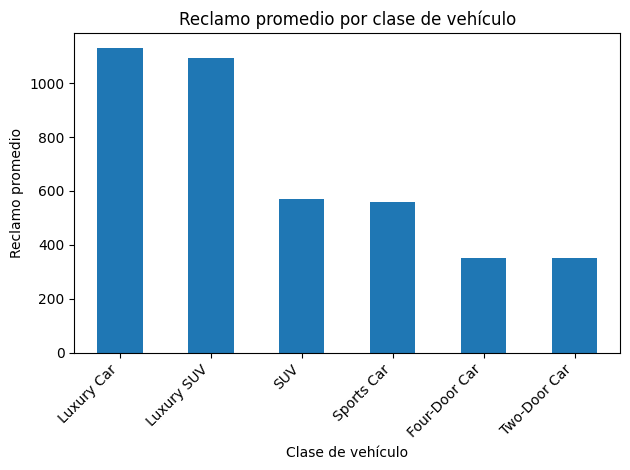

In [49]:
reclamos_vehiculo.plot(kind="bar")
plt.title("Reclamo promedio por clase de vehículo")
plt.xlabel("Clase de vehículo")
plt.ylabel("Reclamo promedio")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [50]:
prima_cobertura = (
    df.groupby("Coverage")["Monthly Premium Auto"]
    .mean()
    .sort_values(ascending=False)
)

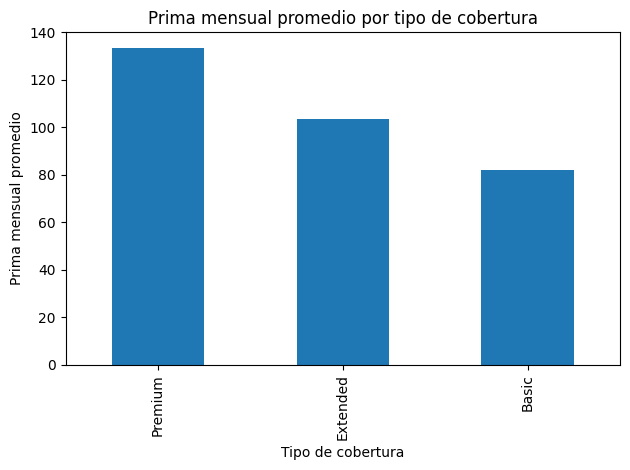

In [51]:
prima_cobertura.plot(kind="bar")
plt.title("Prima mensual promedio por tipo de cobertura")
plt.xlabel("Tipo de cobertura")
plt.ylabel("Prima mensual promedio")
plt.tight_layout()
plt.show()

In [52]:
respuesta_canal = (
    df.assign(Respuesta_Afirmativa=df["Response"].eq("Yes"))
    .groupby("Sales Channel")["Respuesta_Afirmativa"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

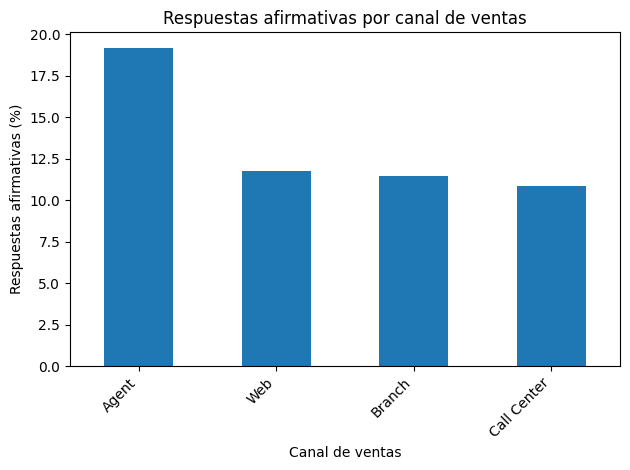

In [53]:
respuesta_canal.plot(kind="bar")
plt.title("Respuestas afirmativas por canal de ventas")
plt.xlabel("Canal de ventas")
plt.ylabel("Respuestas afirmativas (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [54]:
ofertas = df["Renew Offer Type"].value_counts()

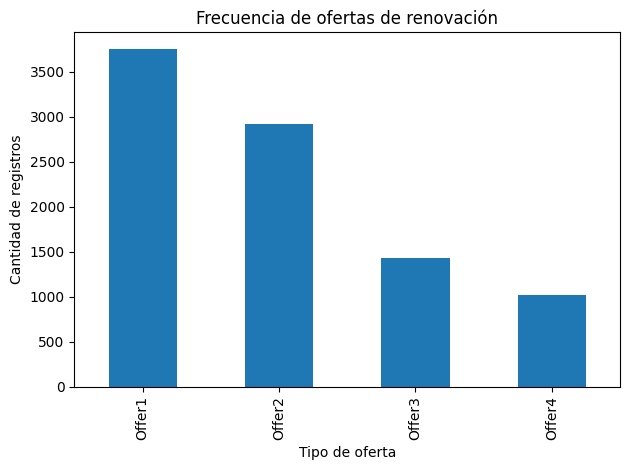

In [55]:
ofertas.plot(kind="bar")
plt.title("Frecuencia de ofertas de renovación")
plt.xlabel("Tipo de oferta")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

In [56]:
reclamos_estado = (
    df.groupby("State")["Total Claim Amount"]
    .mean()
    .sort_values(ascending=False)
)


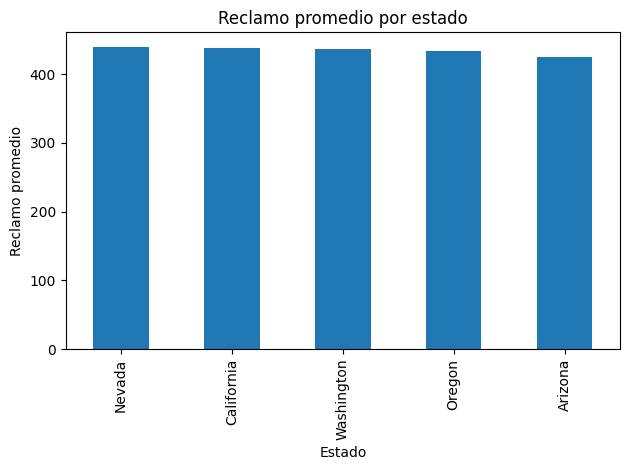

In [57]:
reclamos_estado.plot(kind="bar")
plt.title("Reclamo promedio por estado")
plt.xlabel("Estado")
plt.ylabel("Reclamo promedio")
plt.tight_layout()
plt.show()

El presente analisis permitio identificar que vehiculos presentan el mayor reclamo promedio, siendo el vehiculo Luxury Car, el que presento mayor reclamacion con un valor de 1.130,29 seguidos de Luxury SUV con 1.092,53. Por otra parte los vehiculos Two-Door Car registran un promedio de 350,54. Estos resultados muestran la diferencia que hay entre las clases de vehiculos y se sugiere que seria muy util investigar otros factores que puedan estar relacionados con los valores de los reclamos.

por otro lado, en la relacion que hay entre el tipo de cobertura y la prima mensual, se encontro que la cobertura Premium tiene la prima mensual promedio mas alta, esta con 133,38. mientras que la cobertura Basic presenta un promedio de 82,17. lo cual permite evidenciar diferencias en el valor de las primas segun el tipo de cobertura contratado.

existen diferencias en las respuestas segun el canal de ventas, dado que; el canal Agent presenta el mayor porcentaje de respuestas afirmativas, con  19,15% mientras qye Call Center registra el menor % con 10,88% esta diferencia permite identificar variaciones en la respuesta de los clientes entre los canales de las ventas y asi servir como punto de partida para poder estudiar el comportamiento comercial de la empresa.




